# Deliverable 1: Photo or not? Filtering images with neural networks

**Author**:

| Name | Email |
|---|---|
| Zakarya Zitouni | zakarya.zitouni@viacesi.fr |

**The problem**: the company wants to caption its photos automatically, but the archive also holds paintings, diagrams, drawings and scanned text. Captioning those would be wasted effort, so before anything else we need a model that **keeps the photos** and **filters out everything else**.

**The data**: five archives, one per image type. The images aren't labelled individually, but each archive is a class in itself:

| Archive | What it contains | How hard to tell from a photo |
|---|---|---|
| **Text** | scanned text pages | easy |
| **Sketch** | black and white hand-drawn portraits | fairly easy |
| **Schematics** | diagrams and graphs | medium |
| **Painting** | paintings, some with very realistic rendering | **hard** |
| **Photo** | the photos we want to keep | |

**The plan**:
- **1 to 5**: prepare and explore the data.
- **6 and 7: 5-class classification.** The lecture model as our starting point (6), then our improved CNN (7).
- **8: binary classification**, the deliverable itself: photo vs not photo, with the improved CNN.
- **9**: analysis of the results through the bias / variance trade-off, and next steps.
- **10**: the binary model is saved, reloaded and tested on a complementary folder of images it has never seen.

# 1. Imports, paths and settings

Everything the notebook needs is set up here, once. The tools: `tensorflow` and `keras` for the neural networks, `numpy` for the numbers, `matplotlib` to draw results, `pathlib` to handle folders.

**`data_dir`** is the labelled dataset, one folder per class.

Three settings shared by every model: images are resized to **180x180** pixels and fed in **batches of 32**.

In [10]:
import pathlib
import shutil
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import tensorflow as tf
import keras
from keras import layers
from keras.models import Sequential

# Labelled dataset: one subfolder per class
data_dir = pathlib.Path("/mnt/c/Users/zakar/OneDrive/Desktop/Documents/DataSet")
image_exts = {'.bmp', '.gif', '.jpeg', '.jpg', '.png'}

image_h = 180
image_w = 180
batch_s = 32

# 2. Cleaning the data and counting the classes

Before training anything, we make sure the images are actually usable. A single corrupt file would crash training halfway through an epoch, so this cell decodes every image exactly as the training pipeline will, and **moves** any unreadable one to a `DataSet_removed` folder (nothing is deleted, so it can be undone).

The same scan then counts the images per class. The classes are far from equal: **Sketch** has about 7 times fewer images than the others. Class weights, which make rare classes count more, were tested in section 7 and didn't help, because Sketch is recognised perfectly anyway.

**Note**: as in the workshop, we explore the data *before* building a model. Knowing what is in the dataset (sizes, imbalance, bad files) tells us what to fix, instead of discovering it later through poor results.

In [11]:
removed_dir = data_dir.parent / f"{data_dir.name}_removed"

# is_valid: True if the image can be decoded, False if the file is corrupt
def is_valid(path):
    try:
        tf.io.decode_image(path.read_bytes(), channels=3, expand_animations=False)
        return True
    except Exception:
        return False

paths = sorted(p for p in data_dir.rglob('*') if p.is_file() and p.suffix.lower() in image_exts)
with ThreadPoolExecutor() as pool:
    valid = list(pool.map(is_valid, paths))

corrupt = [p for p, ok in zip(paths, valid) if not ok]
for path in corrupt:
    dest = removed_dir / path.relative_to(data_dir)
    dest.parent.mkdir(parents=True, exist_ok=True)
    shutil.move(str(path), str(dest))
print(f"Moved {len(corrupt)} corrupt images to {removed_dir}\n")

class_names = sorted(p.name for p in data_dir.iterdir() if p.is_dir())
num_classes = len(class_names)
image_classes = [p.relative_to(data_dir).parts[0] for p, ok in zip(paths, valid) if ok]
class_counts = [image_classes.count(name) for name in class_names]
total = sum(class_counts)
for i, name in enumerate(class_names):
    print(f"{i} {name:<12} {class_counts[i]:>6} images  ({class_counts[i] / total:.0%})")

Corrupt JPEG data: 419 extraneous bytes before marker 0xd9
W0000 00:00:1792155005.346509   18317 png_io.cc:96] PNG warning: iCCP: known incorrect sRGB profile


Moved 8 corrupt images to /mnt/c/Users/zakar/OneDrive/Desktop/Documents/DataSet_removed

0 Painting       9988 images  (25%)
1 Photo          9993 images  (25%)
2 Schematics     9306 images  (23%)
3 Sketch         1406 images  (3%)
4 Text           9999 images  (25%)


# 3. Helper functions

Reusable tools, which work for both 5-class and binary models:
- `draw_architecture`: draws the network layer by layer, with output shapes and number of weights.
- `plot_history`: accuracy and loss curves for training and validation.
- `test_model`: final scores on the three sets, a **confusion matrix**, **precision and recall** per class, the error rate per original image type (binary models) and 9 sample predictions.

In [12]:
# plot_history: accuracy and loss curves for training and validation
def plot_history(history):
    h = history.history
    epochs_range = range(1, len(h['accuracy']) + 1)
    plt.figure(figsize=(16, 8))
    for i, (metric, title, loc) in enumerate([('accuracy', 'Accuracy', 'lower right'), ('loss', 'Loss', 'upper right')]):
        plt.subplot(1, 2, i + 1)
        for prefix, name in [('', 'Training'), ('val_', 'Validation')]:
            if prefix + metric in h:
                plt.plot(epochs_range, h[prefix + metric], label=f'{name} {title}')
        plt.xlabel('Epoch')
        plt.legend(loc=loc)
        plt.title(f'Training and Validation {title}')
    plt.show()

# draw_architecture: draws the network layer by layer (what it does, output shape, weights)
def draw_architecture(model, title):
    # describe: name, short explanation and colour of one layer
    def describe(layer):
        kind = type(layer).__name__
        if layer.name == 'data_augmentation':
            return 'Data augmentation', 'flip, rotate, zoom, shift, contrast (training only)', '#D4A6C8'
        if kind == 'Rescaling':
            return kind, 'pixels / 255, values between 0 and 1', '#E0E0E0'
        if kind == 'BatchNormalization':
            return 'BatchNorm', 'rescales each channel to mean 0, variance 1', '#C7B8E0'
        if kind == 'Activation':
            return 'Activation', layer.activation.__name__, '#E8E8E8'
        if kind == 'Conv2D':
            return kind, f'{layer.filters} filters {layer.kernel_size[0]}x{layer.kernel_size[1]}, {layer.activation.__name__}', '#A0CBE8'
        if kind == 'MaxPooling2D':
            return kind, f'{layer.pool_size[0]}x{layer.pool_size[1]} max, halves width and height', '#8CD17D'
        if kind == 'Dropout':
            return kind, f'switches off {layer.rate:.0%} of values (training only)', '#D7D7D7'
        if kind == 'Flatten':
            return kind, 'feature maps unrolled into one long vector', '#FF9D9A'
        if kind == 'GlobalAveragePooling2D':
            return kind, 'one average per feature map', '#FF9D9A'
        if kind == 'Dense':
            act = layer.activation.__name__
            return kind, f'{layer.units} neurons, {"logits (softmax in the loss)" if act == "linear" else act}', '#FFBE7D'
        return kind, '', '#E0E0E0'

    shape = (None, image_h, image_w, 3)
    blocks = [('Input', f'{image_h}x{image_w} RGB image', '#E0E0E0', shape[1:], 0)]
    for layer in model.layers:
        try:
            shape = layer.compute_output_shape(shape)
            out_shape = tuple(shape[1:])
        except Exception:
            out_shape = '?'
        blocks.append((*describe(layer), out_shape, layer.count_params()))

    n = len(blocks)
    fig, ax = plt.subplots(figsize=(12, (0.7 if n <= 20 else 0.42) * n + 1))
    ax.text(7.1, n + 0.1, 'Output shape', fontweight='bold', fontsize=9)
    ax.text(10.2, n + 0.1, 'Weights', fontweight='bold', fontsize=9, ha='right')
    for i, (kind, detail, color, out_shape, params) in enumerate(blocks):
        y = n - 1 - i
        ax.add_patch(patches.FancyBboxPatch((0, y + 0.15), 6.9, 0.7, boxstyle='round,pad=0.02', facecolor=color, edgecolor='#555'))
        ax.text(0.15, y + 0.5, kind, va='center', fontsize=10, fontweight='bold')
        ax.text(2.6, y + 0.5, detail, va='center', fontsize=9)
        ax.text(7.1, y + 0.5, str(out_shape), va='center', fontsize=9)
        ax.text(10.2, y + 0.5, f'{params:,}' if params else '-', va='center', ha='right', fontsize=9)
        if i:
            ax.annotate('', xy=(3.45, y + 0.85), xytext=(3.45, y + 1.15), arrowprops=dict(arrowstyle='->', color='#555'))
    trainable = int(sum(np.prod(w.shape) for w in model.trainable_weights))
    ax.set_title(f'{title}: {model.count_params():,} weights ({trainable:,} trainable)', fontweight='bold')
    ax.set_xlim(-0.1, 10.4)
    ax.set_ylim(-0.1, n + 0.5)
    ax.axis('off')
    plt.show()

# is_binary: True for a photo / not-photo model, False for a 5-class model
def is_binary(model):
    return model.layers[-1].units == 1

# predict_classes: predicted class and confidence for a batch of images
def predict_classes(model, images):
    out = model(images, training=False).numpy()
    if out.shape[-1] == 1:
        p_photo = out[:, 0]
        return (p_photo > 0.5).astype(int), np.maximum(p_photo, 1 - p_photo)
    probs = tf.nn.softmax(out).numpy()
    return probs.argmax(axis=1), probs.max(axis=1)

# test_model: scores, confusion matrix, precision / recall and sample predictions of a trained model
def test_model(model):
    binary = is_binary(model)
    sets = (train_bin, val_bin, test_bin) if binary else (train_set, val_set, test_set)
    names = binary_names if binary else class_names
    _, train_acc = model.evaluate(sets[0], verbose=0)
    _, val_acc = model.evaluate(sets[1], verbose=0)
    test_loss, test_acc = model.evaluate(sets[2], verbose=0)
    print(f"Train accuracy: {train_acc:.2%}")
    print(f"Val accuracy:   {val_acc:.2%}")
    print(f"Test accuracy:  {test_acc:.2%}  |  Test loss: {test_loss:.4f}")
    print(f"Gap train - test: {train_acc - test_acc:+.2%}  |  Gap val - test: {val_acc - test_acc:+.2%}")

    source, predicted, sample = [], [], None
    for images, labels in test_set:
        sample = sample or (images, labels)
        predicted.append(predict_classes(model, images)[0])
        source.append(labels.numpy())
    source, predicted = np.concatenate(source), np.concatenate(predicted)
    truth = (source == photo_idx).astype(int) if binary else source

    cm = tf.math.confusion_matrix(truth, predicted, num_classes=len(names)).numpy()
    plt.figure(figsize=(1.3 * len(names) + 2, 1.2 * len(names) + 1.5))
    plt.imshow(cm, cmap='Blues')
    for r in range(len(names)):
        for c in range(len(names)):
            plt.text(c, r, cm[r, c], ha='center', va='center', color='white' if cm[r, c] > cm.max() / 2 else 'black')
    plt.xticks(range(len(names)), names, rotation=45, ha='right')
    plt.yticks(range(len(names)), names)
    plt.xlabel('Predicted')
    plt.ylabel('True')
    plt.title('Confusion matrix (test set)')
    plt.show()

    precision = cm.diagonal() / np.maximum(cm.sum(axis=0), 1)
    recall = cm.diagonal() / np.maximum(cm.sum(axis=1), 1)
    for i, name in enumerate(names):
        print(f"{name:<12} precision {precision[i]:.2%}   recall {recall[i]:.2%}")

    if binary:
        print("\nError rate per original image type:")
        for i, name in enumerate(class_names):
            mask = source == i
            print(f"{name:<12} {np.mean(predicted[mask] != truth[mask]):6.2%} wrong  ({mask.sum()} images)")

    images, labels = sample
    guesses = predict_classes(model, images)[0]
    labels = labels.numpy()
    if binary:
        labels = (labels == photo_idx).astype(int)
    plt.figure(figsize=(10, 10))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        correct = guesses[i] == labels[i]
        title = names[guesses[i]] if correct else f"{names[guesses[i]]} ({names[labels[i]]})"
        plt.title(title, color='green' if correct else 'red')
        plt.axis("off")
    plt.show()

# 4. Building the training, validation and test sets

The data is split in three, and each part has one job:
- **Test (20%)**: never touched during training, used only for the final verdict.
- **Validation (16%)**: used while training to detect overfitting and stop at the right moment.
- **Train (64%)**: what the model actually learns from.

A fixed `seed=42` keeps the split identical on every run. Decoded images are **cached on disk** because they would not fit in RAM and also cause loading them from the disk without caching would be extremely slow, and the training set is **shuffled** so the model never sees images in the same order.

In [13]:
train_inset = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split= 0.2,
    subset = 'training',
    seed = 42,
    image_size = (image_h, image_w),
    batch_size = batch_s
)
test_set = tf.keras.preprocessing.image_dataset_from_directory(
    data_dir,
    validation_split= 0.2,
    subset = 'validation',
    seed = 42,
    image_size = (image_h, image_w),
    batch_size = batch_s
)
class_names = train_inset.class_names
print(class_names)

file_paths = train_inset.file_paths
file_labels = [class_names.index(pathlib.Path(p).parent.name) for p in file_paths]
val_count = int(0.2 * len(file_paths))

cache_dir = pathlib.Path.home() / "tf-cache" / f"{image_h}x{image_w}"
cache_dir.mkdir(parents=True, exist_ok=True)

# load_image: reads, decodes and resizes one image
def load_image(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize(img, (image_h, image_w)), label

# make_set: loads, caches, shuffles (training only) and batches a list of files
def make_set(paths, labels, name, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(load_image, num_parallel_calls=4).cache(str(cache_dir / name))
    return (ds.shuffle(1000) if shuffle else ds).batch(batch_s).prefetch(tf.data.AUTOTUNE)

val_set = make_set(file_paths[:val_count], file_labels[:val_count], "val")
train_set = make_set(file_paths[val_count:], file_labels[val_count:], "train", shuffle=True)
test_set = test_set.cache(str(cache_dir / "test")).prefetch(tf.data.AUTOTUNE)

Found 40692 files belonging to 5 classes.
Using 32554 files for training.
Found 40692 files belonging to 5 classes.
Using 8138 files for validation.
['Painting', 'Photo', 'Schematics', 'Sketch', 'Text']


# 5. Visualising the data

Before training, let's look at what we are actually feeding the model: 9 images each from the **train**, **validation** and **test** sets, with their class as the title. It is a quick sanity check that images load correctly and that labels match what we see.

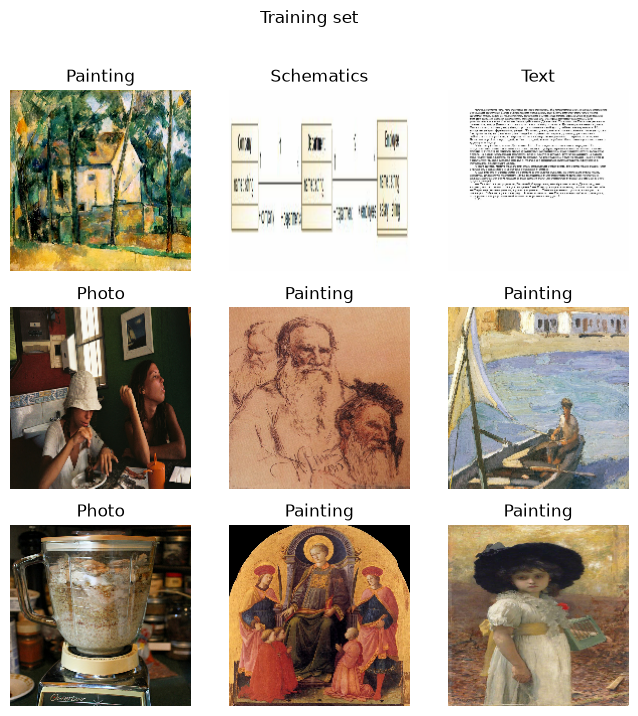

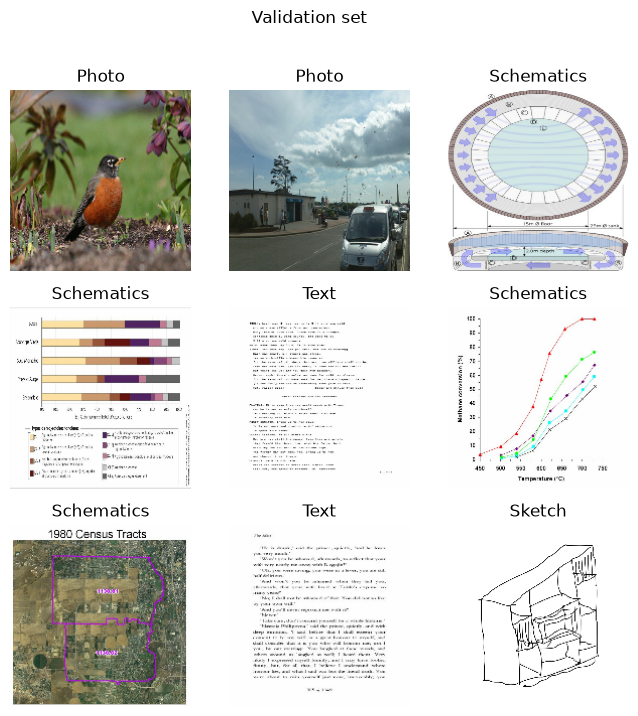

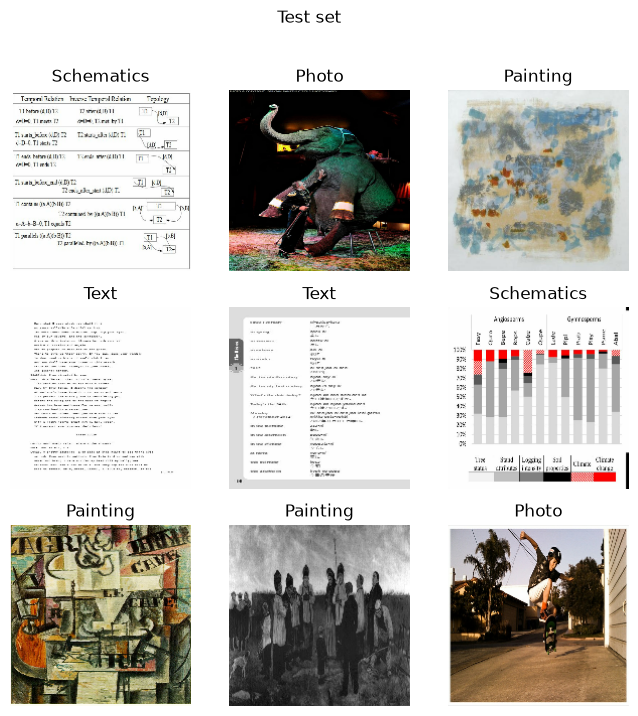

In [14]:
# show_batch: shows the first 9 images of a dataset with their class
def show_batch(dataset, title):
    images, labels = next(iter(dataset))
    plt.figure(figsize=(8, 8))
    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")
    plt.suptitle(title)
    plt.show()

for dataset, title in [(train_set, 'Training set'), (val_set, 'Validation set'), (test_set, 'Test set')]:
    show_batch(dataset, title)

# 6. Starting point: the lecture model from Workshop1

**Workshop 1** built this network to recognise **5 flower species** (daisy, dandelion, roses, sunflowers, tulips) from the TensorFlow flowers dataset: **3,670 photos** in total, about 2,350 of them for training. It compared two versions of the same network:

| Step | Train | Validation | What it showed |
|---|---|---|---|
| **Dropout** 30% only, 15 epochs | 99% | 68% | far too few images: it **memorises** (high variance) |
| Dropout + **data augmentation**, 20 epochs | 85% | 77% | the gap closes: **about 72% on test** |

With so few images, overfitting was the main problem, and augmentation was the cure: a flipped, rotated or zoomed flower is still a believable flower.

Here we keep that final network as the reference: three convolution blocks (32, 64, 128 filters) with max pooling, 30% dropout, then **Flatten** into a dense layer of 128 neurons and one output per class. The only change is slightly stronger augmentation (zoom 20% instead of 10%, plus shifts and contrast).

| Setting | Value |
|---|---|
| Loss | sparse categorical cross-entropy (on logits) |
| Optimiser | Adam, learning rate 0.001 |
| Epochs | fixed at 20 |
| Batch size | 32 |
| Data augmentation | random flip, rotation, zoom, shift and contrast |

Weak points:
- **Flatten + Dense** holds 7.9 million weights (99% of the model): room to memorise, a **variance** risk.
- **Fixed 20 epochs**: nothing stops training at the right moment.
- **No class weights**, although Sketch has 7 times fewer images.

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61952)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │     7,929,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,023,877 (30.61 MB)

 Trainable params: 8,023,877 (30.61 MB)

 Non-trainable params: 0 (0.00 B)

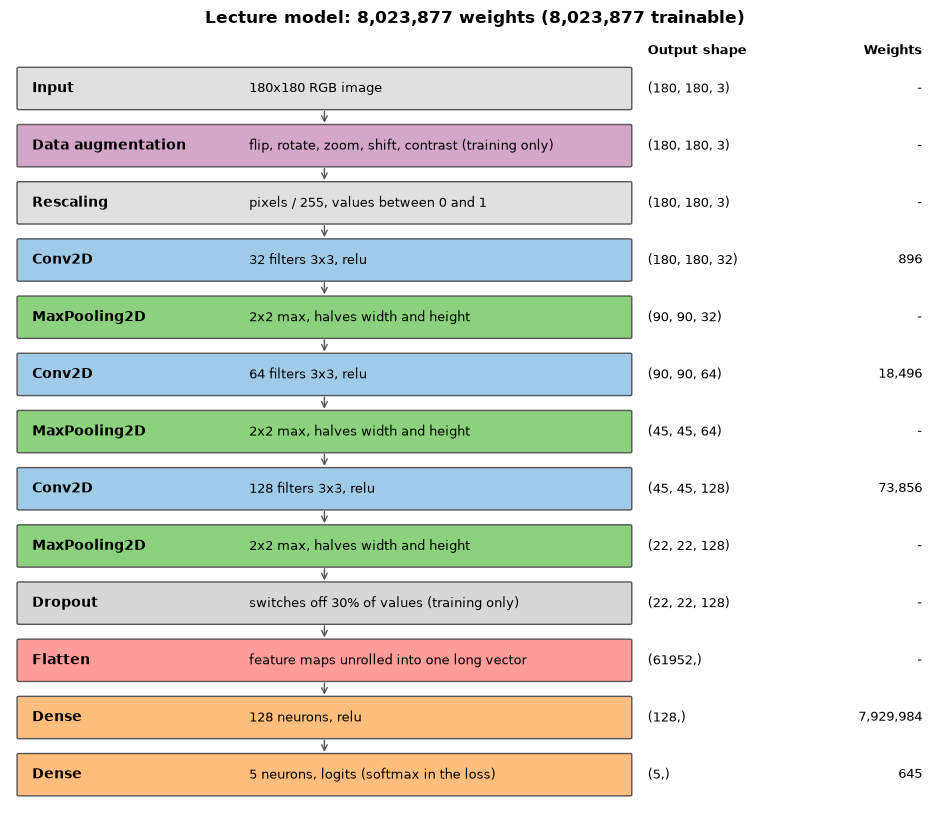

Epoch 1/20


E0000 00:00:1792155042.776864    1171 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/sequential_1_1/dropout_1_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


814/814 ━━━━━━━━━━━━━━━━━━━━ 41s 48ms/step - accuracy: 0.7005 - loss: 0.6888 - val_accuracy: 0.7659 - val_loss: 0.6364
Epoch 2/20
814/814 ━━━━━━━━━━━━━━━━━━━━ 37s 46ms/step - accuracy: 0.7940 - loss: 0.4948 - val_accuracy: 0.7943 - val_loss: 0.5500
Epoch 3/20
814/814 ━━━━━━━━━━━━━━━━━━━━ 37s 46ms/step - accuracy: 0.8292 - loss: 0.4183 - val_accuracy: 0.8240 - val_loss: 0.4499
Epoch 4/20
814/814 ━━━━━━━━━━━━━━━━━━━━ 39s 48ms/step - accuracy: 0.8437 - loss: 0.3827 - val_accuracy: 0.8335 - val_loss: 0.4806
Epoch 5/20
814/814 ━━━━━━━━━━━━━━━━━━━━ 38s 47ms/step - accuracy: 0.8542 - loss: 0.3605 - val_accuracy: 0.8699 - val_loss: 0.3694
Epoch 6/20
814/814 ━━━━━━━━━━━━━━━━━━━━ 39s 48ms/step - accuracy: 0.8643 - loss: 0.3374 - val_accuracy: 0.8601 - val_loss: 0.3748
Epoch 7/20
814/814 ━━━━━━━━━━━━━━━━━━━━ 38s 47ms/step - accuracy: 0.8702 - loss: 0.3286 - val_accuracy: 0.8428 - val_loss: 0.4057
Epoch 8/20
814/814 ━━━━━━━━━━━━━━━━━━━━ 41s 50ms/step - accuracy: 0.8718 - loss: 0.3151 - val_accurac

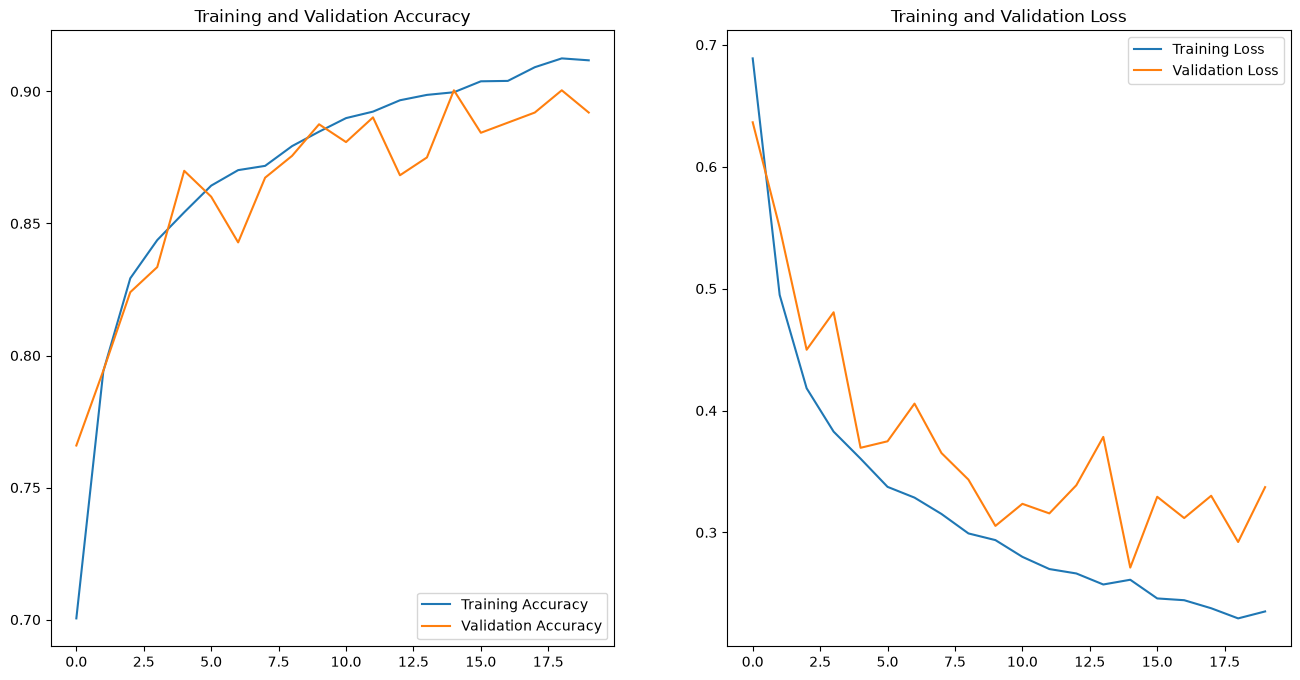

255/255 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - accuracy: 0.8913 - loss: 0.3239
Test accuracy: 89.13%  |  Test loss: 0.3239


In [15]:
# Model from workshop, continuation and improvement.
# Data augmentation, as in the workshop (Keras 3: these layers live directly in keras.layers)
data_augmentation = keras.Sequential(
  [
    layers.Input(shape=(image_h, image_w, 3)),
    layers.RandomFlip("horizontal"),       # mirror left/right
    layers.RandomRotation(0.1),            # rotate by up to ±10% of a full turn (±36°)
    layers.RandomZoom(0.2),                # zoom in/out by up to 20%
    layers.RandomTranslation(0.1, 0.1),    # shift up/down and left/right by up to 10%
    layers.RandomContrast(0.2),            # vary contrast by up to 20% (different lighting)
  ],
  name='data_augmentation'
)
lecture_model = Sequential([
    data_augmentation,
    layers.Rescaling(1./255),
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(num_classes)
])
# Compiling the model
lecture_model.compile(optimizer='adam',
                       loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
                       metrics=['accuracy'])
# Model summary
lecture_model.summary()
draw_architecture(lecture_model, 'Lecture model')
# Model training
# 20 epochs: augmentation makes each epoch "new" data, so the model overfits
# much later and keeps improving longer than the dropout-only version.
epochs = 20
history = lecture_model.fit(train_set, validation_data=val_set, epochs=epochs)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(epochs)

plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()

# Final test: test_set was never used for training or validation, so this is the honest score
test_loss, test_acc = lecture_model.evaluate(test_set)
print(f"Test accuracy: {test_acc:.2%}  |  Test loss: {test_loss:.4f}")

# 7. Improving the lecture model (5 classes)

A model fails in one of two ways:
- **High bias (underfitting)**: too simple, poor on training *and* test data.
- **High variance (overfitting)**: memorises the training set; the train / validation gap widens.

Improving a model means finding which one holds it back, then treating that one.

## Why augmentation held it back

In the workshop (2,350 flower photos), the risk was variance, and augmentation was the right cure. Here it hurts:
- **Our classes differ by texture**: camera noise in a photo, brush strokes in a painting, crisp lines in a diagram.
- **Rotating or zooming smooths those details away**, so the lecture model's training accuracy stalls at 91%: **bias**.
- **We don't need it**: we have 11 times more data, and batch normalisation, dropout and early stopping already regularise.

## Batch normalisation, the key change

After each convolution, **batch normalisation** rescales each channel of the batch to **mean 0 and standard deviation 1**, then applies a **learnt scale and shift**. Each layer always receives well-scaled inputs, which gives:
- **faster, steadier training**,
- **more depth**: deeper networks become trainable,
- **mild regularisation**, from the batch-to-batch noise.

## The changes

| Change | Why |
|---|---|
| **Batch normalisation + deeper blocks** | steadier training and more learning power: fights **bias** |
| **Global average pooling** instead of Flatten | 7 times fewer weights |
| **Cosine learning-rate schedule** | smooth decrease from 0.001 to 0 |
| **No augmentation** | it blurred the texture cues that separate paintings from photos |
| **Label smoothing + weight decay** | less over-confidence and smaller weights: fights **variance** |

### The experiments

Each step was scored on the **validation set**; the test set was used **once**, on the final model. Scores are rounded: retraining moves them by a few tenths of a point.

| # | Model | Validation | What we learnt |
|---|---|---|---|
| 1 | Lecture model | ~91% | the reference |
| 2 | Batch norm + deeper blocks + cosine schedule, light augmentation | ~94% | first clear win |
| 3 | #2 with **no augmentation**, 35 epochs | ~97% | **biggest gain** |
| 4 | #3 + **label smoothing + weight decay** | **~98%** | **final model** |

Also tried, not kept: a 5th block, class weights, 256x256 images and averaging 3 models (no gain, or too costly).

**On the test set: about 97%**, against about 91% for the lecture model. Painting about 97%, Photo about 95%.

### The final improved CNN

Four blocks of **two 3x3 convolutions** (32, 64, 128, 256 filters), each with **batch normalisation** and ReLU, then max pooling. Then **global average pooling**, **30% dropout** and one output per class: 1.2 million weights.

| Setting | Value |
|---|---|
| Loss | categorical cross-entropy on logits, **label smoothing 0.1** |
| Optimiser | **AdamW** (weight decay 0.0001), **cosine decay** from 0.001 to 0 |
| Epochs | 35, **early stopping** (patience 10, best weights restored) |
| Batch size | 32 |
| Augmentation / class weights | none |
| Precision | **mixed precision** (output layer in float32) |

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 180, 180, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 90, 90, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 90, 90, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 45, 45, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 45, 45, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             

 Total params: 1,176,421 (4.49 MB)

 Trainable params: 1,174,501 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

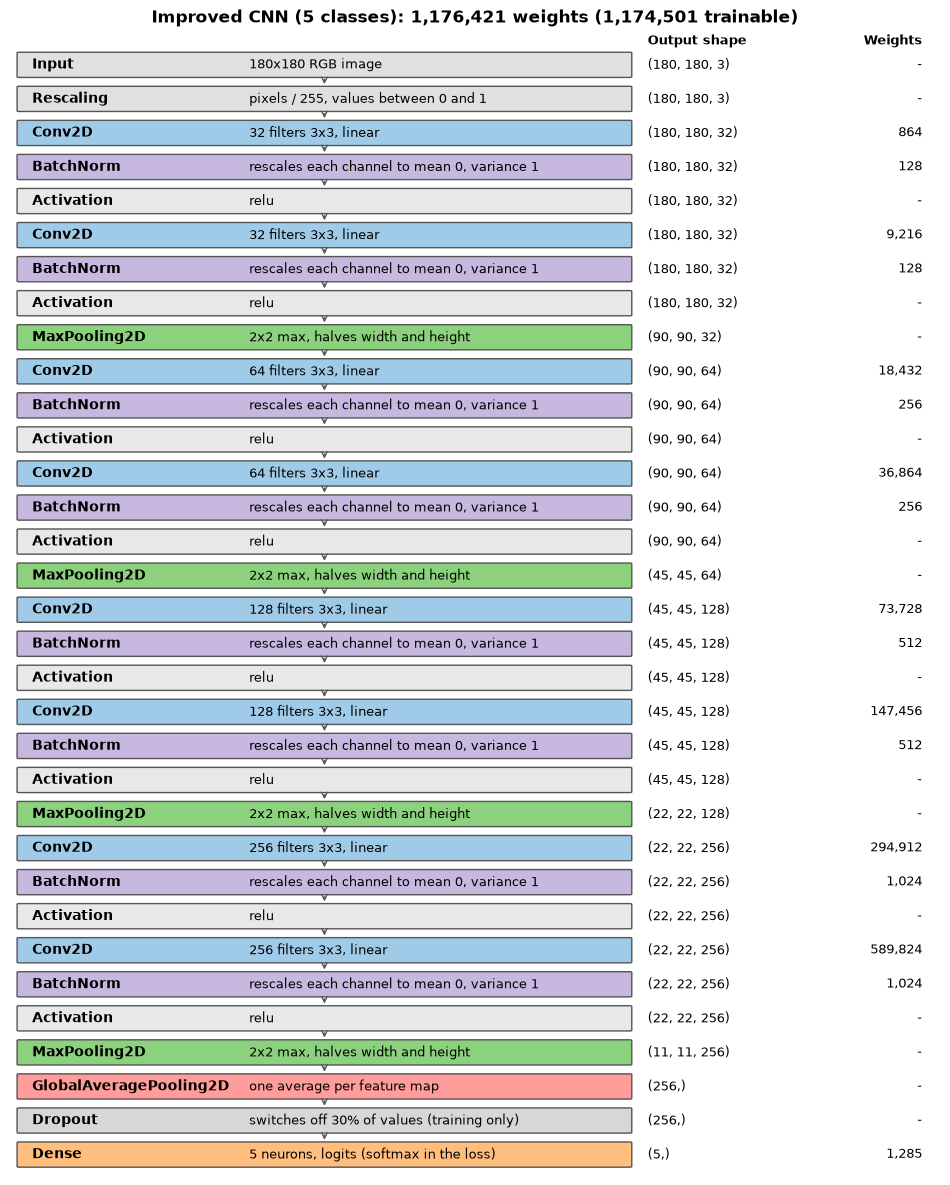

Epoch 1/35


I0000 00:00:1792156319.904233    8745 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_416664__.125


814/814 ━━━━━━━━━━━━━━━━━━━━ 45s 46ms/step - accuracy: 0.7439 - loss: 0.8737 - val_accuracy: 0.6451 - val_loss: 1.0381
Epoch 2/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 44ms/step - accuracy: 0.8260 - loss: 0.7453 - val_accuracy: 0.8464 - val_loss: 0.7030
Epoch 3/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 35s 43ms/step - accuracy: 0.8594 - loss: 0.6853 - val_accuracy: 0.6316 - val_loss: 0.9436
Epoch 4/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 44ms/step - accuracy: 0.8790 - loss: 0.6473 - val_accuracy: 0.8206 - val_loss: 0.7916
Epoch 5/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.8953 - loss: 0.6141 - val_accuracy: 0.6097 - val_loss: 1.0820
Epoch 6/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.9057 - loss: 0.5977 - val_accuracy: 0.8745 - val_loss: 0.6683
Epoch 7/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 44ms/step - accuracy: 0.9155 - loss: 0.5749 - val_accuracy: 0.9165 - val_loss: 0.5934
Epoch 8/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 44ms/step - accuracy: 0.9248 - loss: 0.5610 - val_accurac

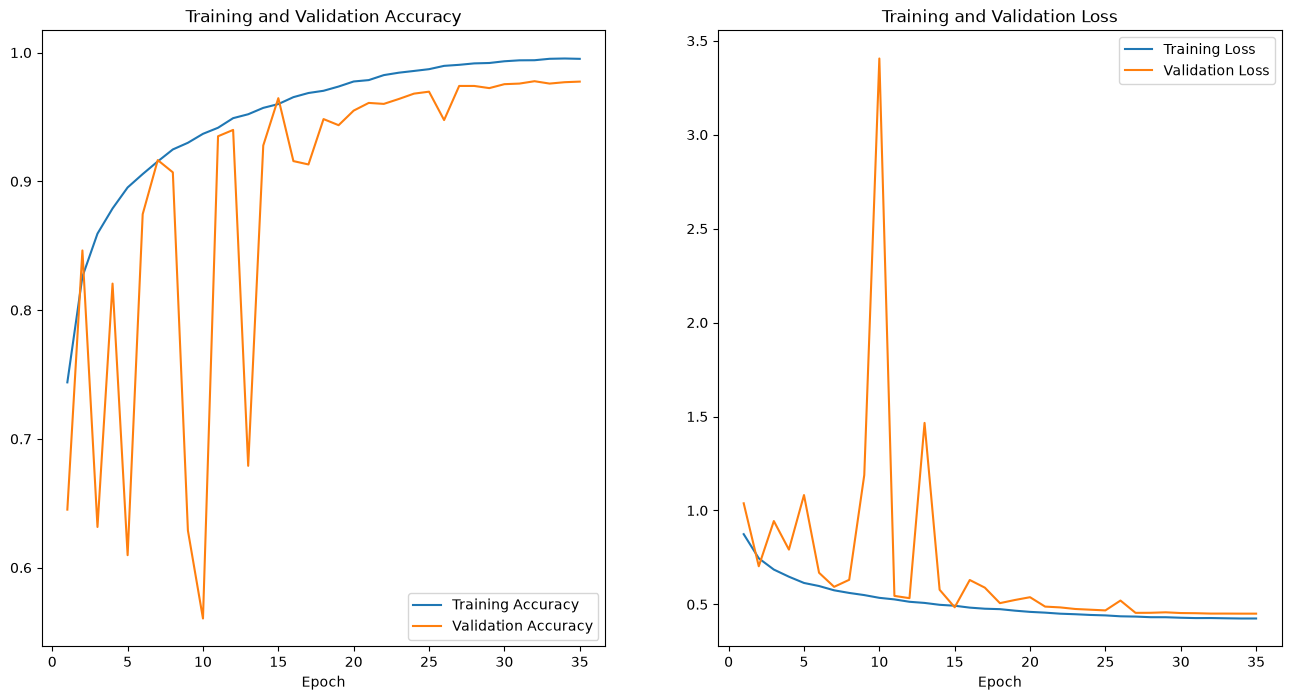

In [18]:
tf.keras.backend.clear_session()
# Mixed precision: float16 maths on the GPU tensor cores for faster training. Only this model uses it.
keras.mixed_precision.set_global_policy('mixed_float16')

def conv_block(filters):
    """Two 3x3 convolutions, each followed by batch normalisation and ReLU, then max pooling."""
    block = []
    for _ in range(2):
        block += [layers.Conv2D(filters, (3, 3), padding='same', use_bias=False),   # batch norm brings its own bias
                  layers.BatchNormalization(),
                  layers.Activation('relu')]
    return block + [layers.MaxPooling2D(pool_size=(2, 2))]

improved_model = Sequential([
    layers.Input(shape=(image_h, image_w, 3)),   # no data augmentation: see experiment 3
    layers.Rescaling(1./255),
    *conv_block(32),
    *conv_block(64),
    *conv_block(128),
    *conv_block(256),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, dtype='float32')   # logits stay in float32 for a stable loss
])
keras.mixed_precision.set_global_policy('float32')   # back to normal for the models that follow

epochs = 35
# Cosine decay: the learning rate glides from 0.001 down to 0 over the whole training instead of being cut in steps
lr_schedule = keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=epochs * len(train_set))
# smoothed_loss: cross-entropy with label smoothing (targets 92% / 2% instead of 100% / 0%)
def smoothed_loss(y_true, y_pred):
    y_true = tf.one_hot(tf.cast(tf.reshape(y_true, [-1]), tf.int32), num_classes)
    return keras.losses.categorical_crossentropy(y_true, y_pred, from_logits=True, label_smoothing=0.1)

improved_model.compile(optimizer=keras.optimizers.AdamW(lr_schedule, weight_decay=1e-4),
                       loss=smoothed_loss,
                       metrics=[keras.metrics.SparseCategoricalAccuracy(name='accuracy')])
improved_model.summary()
draw_architecture(improved_model, 'Improved CNN (5 classes)')
early_stop_cnn = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
# No class_weight: tested, no gain
history = improved_model.fit(train_set, validation_data=val_set, epochs=epochs, callbacks=[early_stop_cnn])
plot_history(history)

### Evaluation

Scores on the three sets: **test close to validation** means the model generalises, **test far below train** means it overfits. The **confusion matrix** and **precision / recall** show which classes get mixed up. The lecture model scored **about 91%** on test.

Train accuracy: 99.75%
Val accuracy:   97.75%
Test accuracy:  97.24%  |  Test loss: 0.4584
Gap train - test: +2.51%  |  Gap val - test: +0.51%


E0000 00:00:1792157594.996827    1171 util.cc:131] oneDNN supports DT_HALF only on platforms with AVX-512. Falling back to the default Eigen-based implementation if present.


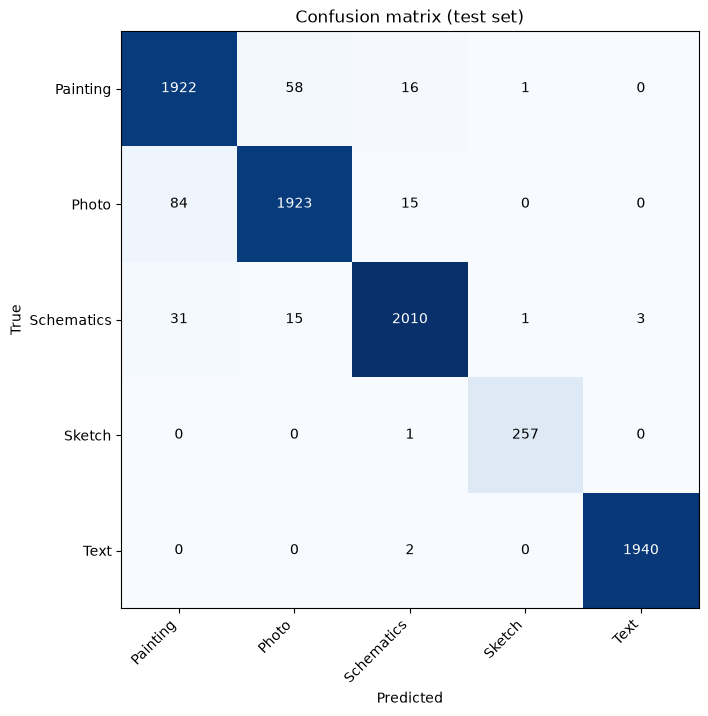

Painting     precision 94.35%   recall 96.24%
Photo        precision 96.34%   recall 95.10%
Schematics   precision 98.34%   recall 97.57%
Sketch       precision 99.23%   recall 99.61%
Text         precision 99.85%   recall 99.90%


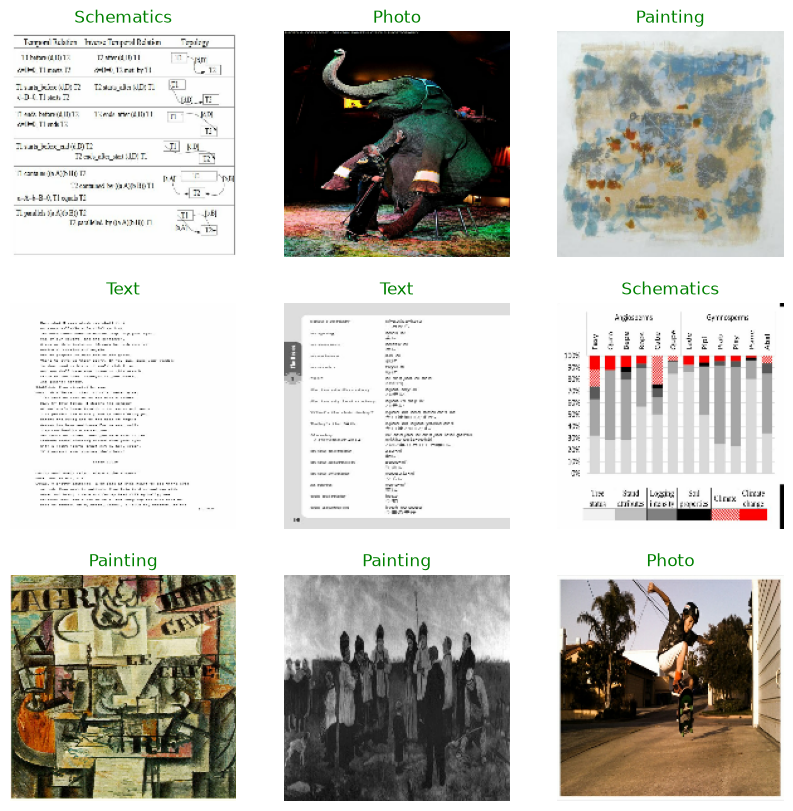

In [19]:
test_model(improved_model)

# 8. Binary classification: photo vs not photo (CNN)

The core of the deliverable: keep the **photos**, filter out **everything else**. Same images and split, relabelled **1 = Photo**, **0 = Not photo**.

The network is the **improved CNN from section 7**, ending with a **single sigmoid neuron**: the probability that the image is a photo (above 0.5 → photo).

| Setting | Value |
|---|---|
| Loss | **binary cross-entropy** |
| Optimiser | **Adam**, **cosine decay** from 0.001 to 0 |
| Epochs | 35, **early stopping** (patience 10, best weights restored) |
| Batch size | 32 |
| Augmentation / class weights | none |

**Class weights** (photos are 1 image in 4): about the same validation accuracy (97%) with or without them. They find more photos but let more paintings through, so we leave them out.

Photo: 9993 images | Not photo: 30699 images


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 180, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 180, 180, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_8 (Activation)       │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 180, 180, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 180, 180, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_9 (Activation)       │ (None, 180, 180, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 90, 90, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_10 (Activation)      │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 90, 90, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 90, 90, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_11 (Activation)      │ (None, 90, 90, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 45, 45, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_12 (Activation)      │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 45, 45, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_13          │ (None, 45, 45, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_13 (Activation)      │ (None, 45, 45, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 22, 22, 128)    │             

 Total params: 1,175,393 (4.48 MB)

 Trainable params: 1,173,473 (4.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

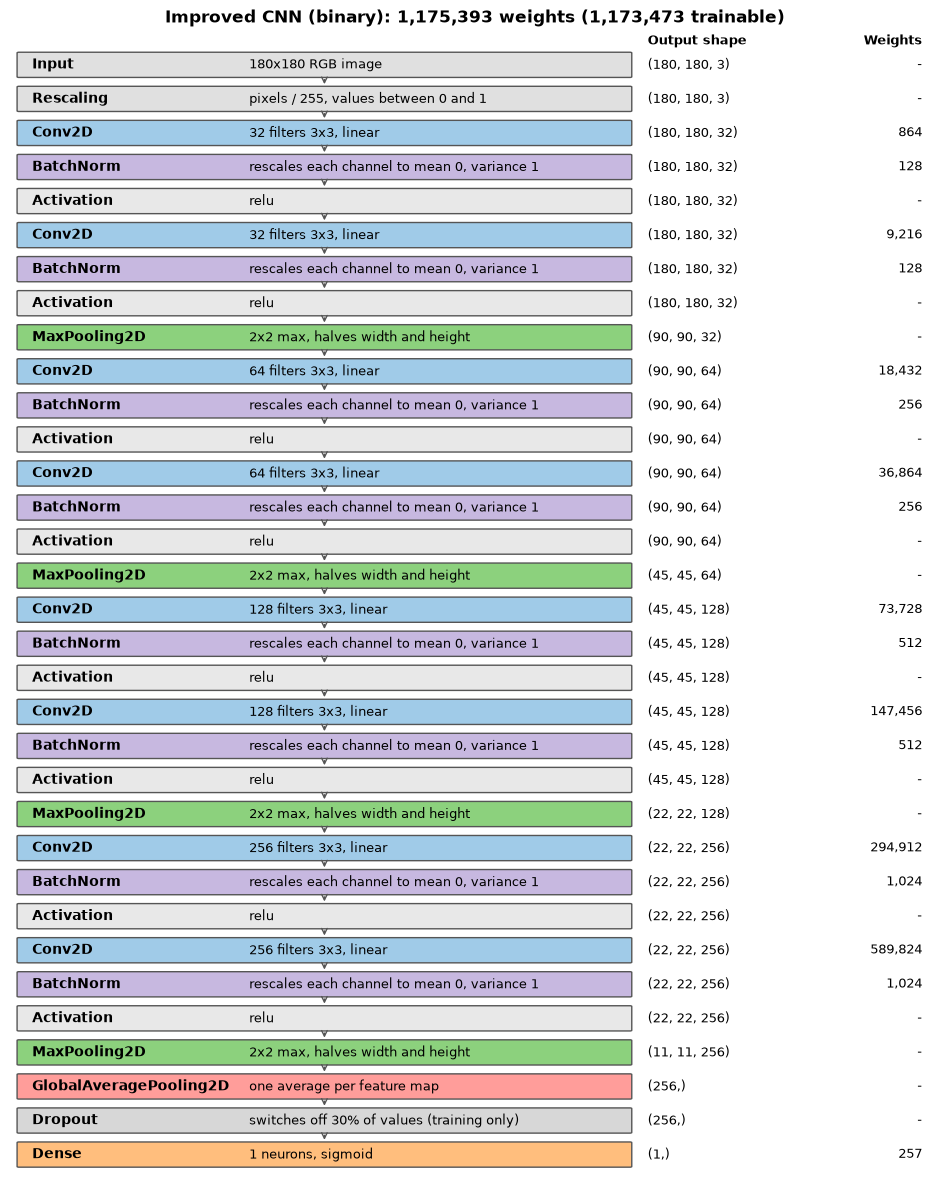

Epoch 1/35


/home/zakar/tf-env/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


814/814 ━━━━━━━━━━━━━━━━━━━━ 46s 45ms/step - accuracy: 0.8109 - loss: 0.3638 - val_accuracy: 0.8179 - val_loss: 0.3403
Epoch 2/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.8565 - loss: 0.3060 - val_accuracy: 0.7667 - val_loss: 0.7705
Epoch 3/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.8738 - loss: 0.2796 - val_accuracy: 0.8859 - val_loss: 0.2783
Epoch 4/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.8904 - loss: 0.2512 - val_accuracy: 0.8883 - val_loss: 0.2810
Epoch 5/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 35s 43ms/step - accuracy: 0.9004 - loss: 0.2360 - val_accuracy: 0.8848 - val_loss: 0.2903
Epoch 6/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 36s 43ms/step - accuracy: 0.9105 - loss: 0.2159 - val_accuracy: 0.9082 - val_loss: 0.2298
Epoch 7/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 35s 43ms/step - accuracy: 0.9207 - loss: 0.1918 - val_accuracy: 0.8853 - val_loss: 0.4441
Epoch 8/35
814/814 ━━━━━━━━━━━━━━━━━━━━ 35s 43ms/step - accuracy: 0.9256 - loss: 0.1804 - val_accurac

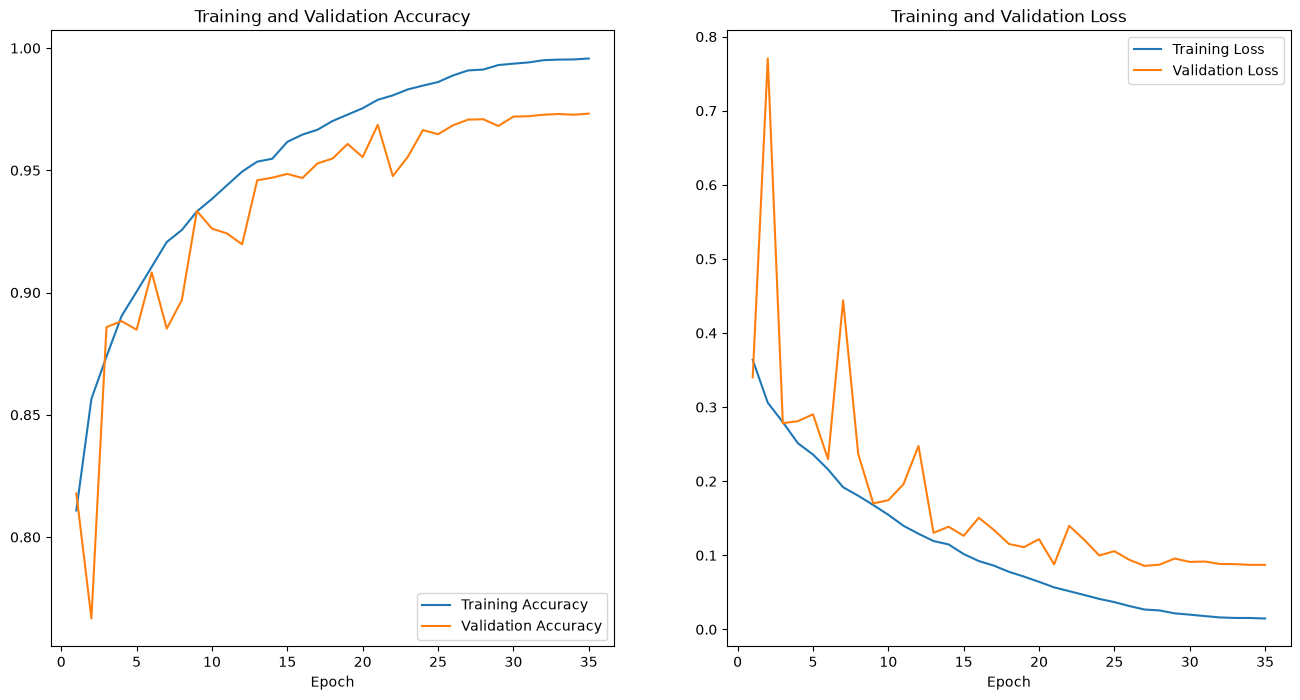

Train accuracy: 99.49%
Val accuracy:   97.07%
Test accuracy:  96.99%  |  Test loss: 0.0876
Gap train - test: +2.51%  |  Gap val - test: +0.09%


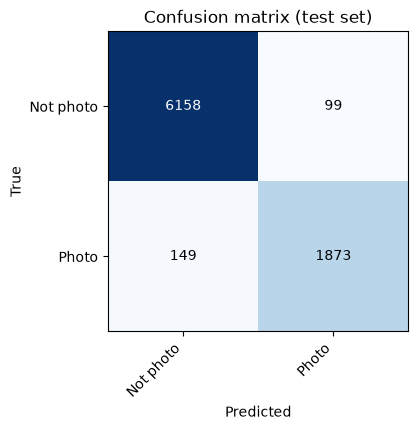

Not photo    precision 97.64%   recall 98.42%
Photo        precision 94.98%   recall 92.63%

Error rate per original image type:
Painting      3.46% wrong  (1997 images)
Photo         7.37% wrong  (2022 images)
Schematics    1.46% wrong  (2060 images)
Sketch        0.00% wrong  (258 images)
Text          0.00% wrong  (1942 images)


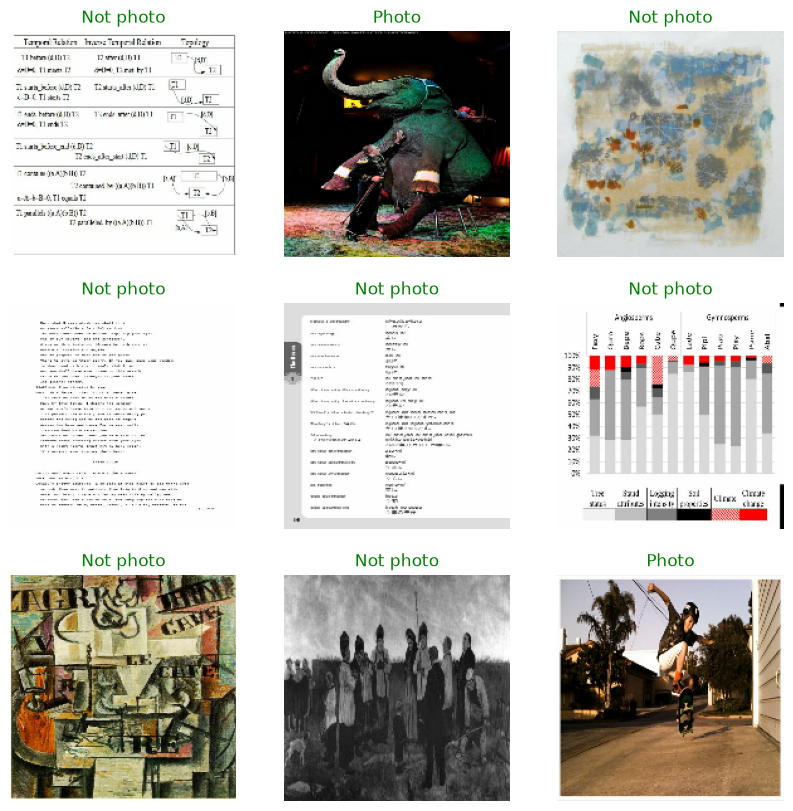

In [20]:
# Relabel the existing sets: 1 = Photo, 0 = anything else. The cached images are reused as is.
photo_idx = class_names.index('Photo')
binary_names = ['Not photo', 'Photo']
to_binary = lambda x, y: (x, tf.cast(tf.equal(y, photo_idx), tf.float32))
train_bin = train_set.map(to_binary)
val_bin = val_set.map(to_binary)
test_bin = test_set.map(to_binary)

n_photo = class_counts[photo_idx]
print(f"Photo: {n_photo} images | Not photo: {total - n_photo} images")

# Same network as section 7 (conv_block is defined there), ending with one sigmoid neuron
keras.mixed_precision.set_global_policy('mixed_float16')
binary_model = Sequential([
    layers.Input(shape=(image_h, image_w, 3)),
    layers.Rescaling(1./255),
    *conv_block(32),
    *conv_block(64),
    *conv_block(128),
    *conv_block(256),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid', dtype='float32')   # probability that the image is a photo
])
keras.mixed_precision.set_global_policy('float32')

epochs = 35
lr_schedule = keras.optimizers.schedules.CosineDecay(1e-3, decay_steps=epochs * len(train_bin))
binary_model.compile(optimizer=keras.optimizers.Adam(lr_schedule), loss='binary_crossentropy', metrics=['accuracy'])
binary_model.summary()
draw_architecture(binary_model, 'Improved CNN (binary)')
early_stop_bin_cnn = keras.callbacks.EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)
history_bin = binary_model.fit(train_bin, validation_data=val_bin, epochs=epochs, callbacks=[early_stop_bin_cnn])
plot_history(history_bin)

test_model(binary_model)

# 9. Analysis: bias vs variance

## 5-class models

| Model | Train | Validation | Test | Weights |
|---|---|---|---|---|
| 6. Lecture model | ~91%\* | ~91% | ~91% | 8.0 M |
| 7. Improved CNN | ~100% | ~98% | **~97%** | 1.2 M |

\* last epoch, with augmentation and dropout on. All scores are rounded: retraining moves them by a few tenths of a point, since weights start at random.

**The lecture model is stuck between bias and variance.** With augmentation, training is capped at 91% (**bias**); without it, 99% on training but 89% on validation (**variance**).

**The improved CNN breaks that trade-off: about +6 points on test.** Batch normalisation, deeper blocks and removing augmentation cut the **bias**; label smoothing and weight decay then cut the **variance**. The train − test gap (2 to 3 points) is small, with 7 times fewer weights.

**What's left**: painting ↔ photo, as the brief predicted: about 2% of paintings are called "photo" and about 5% of photos "painting".

## Binary model (photo vs not photo)

| Model | Train | Validation | Test |
|---|---|---|---|
| 8. Improved CNN | ~99% | ~97% | **~97%** |

Low bias and a small variance gap again. On the test set, **about 3% of images are wrong**: **photo precision about 95%**, **recall about 94%**.

**What it got wrong, by original image type:**

| Image type | Error rate | Mistake |
|---|---|---|
| Photo | **~6%** | missed: called "not photo" |
| Painting | **~4%** | let through as "photo" |
| Schematics | ~1% | let through as "photo" |
| Sketch | 0% | |
| Text | 0% | |

- **Missed photos are the bigger problem**: more than half of the errors.
- **Non-photos let through: under 2%**, and about three quarters of them are paintings.
- **Many errors are confident**: about 40% of the mistakes were made with over 90% confidence. Only about a third are close calls (under 70%), so a threshold change can't fix most of them.

**Precision or recall?** A false "photo" means a painting gets captioned; a missed photo is never captioned. The **decision threshold** trades one for the other without retraining:

| Threshold | Accuracy | Photo precision | Photo recall | Paintings let through |
|---|---|---|---|---|
| 0.3 | ~97% | ~94% | ~96% | ~5% |
| **0.5** (default) | ~97% | ~95% | ~94% | ~4% |
| 0.7 | ~97% | ~97% | ~91% | ~3% |
| 0.9 | ~96% | ~98% | ~84% | ~2% |

Which threshold to pick is a business decision.

# 10. Testing Model on the complementary dataset

The binary model (section 8) is the deliverable, so it is **saved to a file**: the architecture, the trained weights and the optimiser state, everything needed to use it again without retraining.

It is then **loaded back** from that file and tested on images that are **not part of the dataset** at all: every picture in the complementary folder is shown with the predicted class and the model's confidence. To try your own images, put them in that folder and run the cell again.

In [21]:
model_path = pathlib.Path("modele_photo.keras")
binary_model.save(model_path)                              # architecture + trained weights + optimizer state
print("Model saved to", model_path.resolve())

Model saved to /mnt/c/Users/zakar/OneDrive/Desktop/CESI Learning/deliverable1/modele_photo.keras


/home/zakar/tf-env/lib/python3.12/site-packages/keras/src/saving/saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'adam', because it has 53 variables whereas the saved optimizer has 57 variables. 
  saveable.load_own_variables(store)


2 test images found in /mnt/c/Users/zakar/OneDrive/Pictures/test
Screenshot 2025-04-07 at 12.20.59 PM.png -> not a photo  (89.6%)
images.png       -> not a photo  (94.0%)


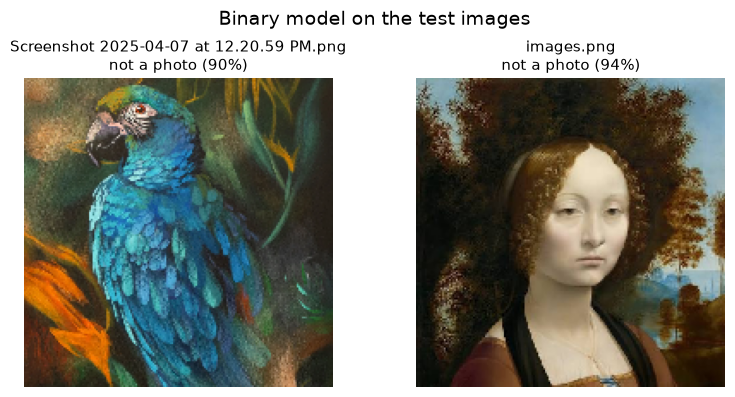

In [22]:
import math

# The binary model of section 8 (run the cell above first: it saves it)
if not model_path.exists():
    raise FileNotFoundError("modele_photo.keras not found: run the cell above first")
model = tf.keras.models.load_model(model_path)
names = ["not a photo", "photo"]

# Test images: every image of the complementary folder
test_dir = pathlib.Path('/mnt/c/Users/zakar/OneDrive/Pictures/test')
image_paths = sorted(p for p in test_dir.iterdir() if p.suffix.lower() in image_exts)
print(f"{len(image_paths)} test images found in {test_dir}")

cols = min(len(image_paths), 4)
rows = math.ceil(len(image_paths) / cols)                    # the grid adapts to the number of images
plt.figure(figsize=(4 * cols, 4 * rows))
for i, path in enumerate(image_paths):
    img = tf.keras.utils.load_img(path, target_size=(image_h, image_w))
    x = tf.expand_dims(tf.keras.utils.img_to_array(img), 0)
    p_photo = float(model.predict(x, verbose=0)[0][0])      # sigmoid output: probability of "photo"
    pred = int(p_photo > 0.5)
    confidence = p_photo if pred else 1 - p_photo

    print(f"{path.name:<16} -> {names[pred]:<12} ({confidence:.1%})")

    plt.subplot(rows, cols, i + 1)
    plt.imshow(np.array(img).astype("uint8"))
    plt.title(f"{path.name}\n{names[pred]} ({confidence:.0%})", fontsize=11)
    plt.axis("off")
plt.suptitle("Binary model on the test images", fontsize=14)
plt.tight_layout()
plt.show()